# Procedure families compared: Ajuste Direto vs Concurso público vs Consulta Prévia

Three families defined by accent-folded, lowercased prefix of `tipo_procedimento`. Everything else is `other`
(framework agreements, excluded contracting, limited tender, …). Entities are keyed by NIPC; the `-` sentinel
falls back to name similarity (`key_source`).

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
    normalize_name,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

FAMILIES = ["ajuste_direto", "concurso_publico", "consulta_previa"]

rows=2,295,074  cols=30
disregarded 12,658 contracts with |preco_contratual| < €10 (0.55%); kept 2,282,416
valor_por_dia defined for 97.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬─────────┐
│ adjudicante_key_source ┆ count   │
│ ---                    ┆ ---     │
│ str                    ┆ u32     │
╞════════════════════════╪═════════╡
│ nipc                   ┆ 2282390 │
│ name                   ┆ 26      │
└────────────────────────┴─────────┘


In [3]:
contracts_all.filter(pl.col("preco_contratual") < 1)

idcontrato,ano,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,desc_contrato,preco_contratual,preco_total_efetivo,preco_base_procedimento,prazo_execucao,valor_por_dia,data_celebracao,data_publicacao,data_fecho,tipo_contrato,tipo_procedimento,fundament_ajuste_direto,cpv,nuts,concorrentes,n_concorrentes,is_municipio,is_below_min_value,row_hash,first_ingested_at,updated_at
i64,i32,str,str,str,str,str,str,str,str,f64,f64,f64,i64,f64,date,date,date,str,str,str,str,str,str,u32,bool,bool,i64,"datetime[μs, UTC]","datetime[μs, UTC]"
10302704,2023,"""514310774 - Águas do Douro e P…","""514310774""","""Águas do Douro e Paiva, SA""","""514310774""","""nipc""",null,"""2022_077AQ - Acordo Quadro par…","""2022_077AQ - Acordo Quadro par…",0.0,0.0,0.0,1460,0.0,2023-03-15,2023-10-20,null,"""Locação de bens móveis""","""Concurso público""",null,"""cpvID=34100000-8|cpvdescricao=…",null,"""502584866-Kinto, Portugal, SA …",4,false,true,-523973382281608643,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
10355349,2023,"""600083233 - Agrupamento de Esc…","""600083233""","""Agrupamento de Escolas n.º 2 d…","""600083233""","""nipc""","""501261648 - Ramos & Pereira, L…","""Aquisição de bens para os bufe…","""Aquisição de bens para os bufe…",0.87,0.87,0.0,366,0.002377,2023-09-08,2023-11-22,2024-09-30,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=15555100-4|cpvdescricao=…",null,null,null,false,true,1087715017699531973,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11533425,2025,"""506605949 - Município de Alvai…","""506605949""","""Município de Alvaiázere""","""506605949""","""nipc""","""500906181 - SABSEG - CORRETOR …","""Aquisição de serviços de consu…","""Aquisição de serviços de consu…",0.0,0.0,0.0,1096,0.0,2025-06-23,2025-06-24,null,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,"""cpvID=66518000-4|cpvdescricao=…","""PT16F - Região de Leiria""",null,null,true,true,4116407151759990989,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
9431950,2022,"""504475606 - Municípia, Empresa…","""504475606""","""Municípia, Empresa de Cartogra…","""504475606""","""nipc""",null,"""Acordo Quadro para a Prestação…","""Acordo Quadro para a Prestação…",0.0,0.0,84878.09,1460,0.0,2022-08-05,2022-09-01,null,"""Aquisição de serviços""","""Concurso limitado por prévia q…",null,"""cpvID=79710000-4|cpvdescricao=…",null,null,null,false,true,-4672021374756670566,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
10271362,2023,"""600012662 - MARINHA - Direção …","""600012662""","""MARINHA - Direção de Abastecim…","""600012662""","""nipc""",null,"""3023011517/Fornecimento de Med…","""3023011517/Fornecimento de Med…",0.0,0.0,89.6,5,0.0,2023-10-01,2023-10-02,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33690000-3|cpvdescricao=…",null,null,null,false,true,-491519113205067839,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
2954599,2016,"""508878462 - Unidade Local de S…","""508878462""","""Unidade Local de Saúde de Entr…","""508878462""","""nipc""","""505792362 - OVERPHARMA- PRODUT…","""Agulhas Hipodérmicas""","""06/00001.23/2016""",0.0,0.0,10387.52,365,0.0,2016-07-15,2017-01-26,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33140000-3|cpvdescricao=…",null,null,null,false,true,5201296831145759312,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
9520034,2022,"""501288120 - Município de Alvit…","""501288120""","""Município de Alvito""","""501288120""","""nipc""","""500906181 - SABSEG - CORRETOR …","""Prestação de serviços de corre…","""Prestação de serviços de corre…",0.0,0.0,0.0,1096,0.0,2022-10-04,2022-10-26,2025-10-05,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""","""ausência de recursos próprios""","""cpvID=66518100-5|cpvdescricao=…",null,"""500906181-SABSEG - CORRETOR DE…",1,true,true,756184238061119

In [4]:
tp = (
    pl.col("tipo_procedimento").str.to_lowercase().str.replace_all("ú", "u").str.replace_all("é", "e")
)
FAMILY = (
    pl.when(tp.str.starts_with("ajuste direto")).then(pl.lit("ajuste_direto"))
    .when(tp.str.starts_with("concurso publico")).then(pl.lit("concurso_publico"))
    .when(tp.str.starts_with("consulta previa")).then(pl.lit("consulta_previa"))
    .otherwise(pl.lit("other"))
    .alias("family")
)
contracts_all = contracts_all.with_columns(FAMILY)
contracts = contracts.with_columns(FAMILY)
counts = contracts_all["family"].value_counts(sort=True)
display(counts)
fam_all = contracts_all.filter(pl.col("family").is_in(FAMILIES))  # before the €10 filter
fam = contracts.filter(pl.col("family").is_in(FAMILIES))
assert set(counts["family"]) >= set(FAMILIES) and counts["count"].sum() == contracts_all.height
print(f"three families cover {fam_all.height:,} of {contracts_all.height:,} rows ({fam_all.height / contracts_all.height:.1%}); after the €10 filter: {fam.height:,}")

family,count
str,u32
"""ajuste_direto""",1364253
"""consulta_previa""",335283
"""other""",325193
"""concurso_publico""",270345


three families cover 1,969,881 of 2,295,074 rows (85.8%); after the €10 filter: 1,958,863


In [5]:
headline = (
    fam.group_by("family")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
        pl.col("preco_contratual").mean().round(0).alias("mean_value"),
        pl.col("preco_contratual").median().alias("median_value"),
    )
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum()).round(3).alias("count_share"),
        (pl.col("total_value") / pl.col("total_value").sum()).round(3).alias("value_share"),
    )
    .sort("n_contracts", descending=True)
)
headline

family,n_contracts,total_value,mean_value,median_value,count_share,value_share
str,u32,f64,f64,f64,f64,f64
"""ajuste_direto""",1357196,3.5737e10,26331.0,8700.0,0.693,0.289
"""consulta_previa""",334550,1.1121e10,33241.0,19900.0,0.171,0.09
"""concurso_publico""",267117,7.6954e10,288090.0,55798.08,0.136,0.622


In [6]:
# Effect of disregarding contracts with |value| below €10, per family.
for f in FAMILIES:
    print(f)
    display(value_impact(fam_all.filter(pl.col("family") == f), fam.filter(pl.col("family") == f)))

ajuste_direto


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",1.364253e6,1.357196e6,-7057.0,-0.52
"""mean_value""",26195.179236,26331.370191,136.190955,0.52
"""median_value""",8615.47,8700.0,84.53,0.98
"""total_value""",3.5737e10,3.5737e10,-21560.490005,-0.0


concurso_publico


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",270345.0,267117.0,-3228.0,-1.19
"""mean_value""",284650.452469,288090.332675,3439.880205,1.21
"""median_value""",54147.72,55798.08,1650.36,3.05
"""total_value""",7.6954e10,7.6954e10,-1179.75,-0.0


consulta_previa


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",335283.0,334550.0,-733.0,-0.22
"""mean_value""",33168.25254,33240.920174,72.667634,0.22
"""median_value""",19868.6,19900.0,31.4,0.16
"""total_value""",1.1121e10,1.1121e10,-1372.260004,-0.0


In [7]:
# Consolidated effect of disregarding contracts priced below €10 (before -> after), all scopes.
is_mun = pl.col("adjudicante_name").map_elements(normalize_name, return_dtype=pl.String).str.starts_with("municipio")
all_m = contracts_all.with_columns(is_mun.alias("is_mun"))
kept_m = contracts.with_columns(is_mun.alias("is_mun"))
scopes = {
    "all contracts": (contracts_all, contracts),
    **{f: (contracts_all.filter(pl.col("family") == f), contracts.filter(pl.col("family") == f)) for f in FAMILIES},
    "município (all procedures)": (all_m.filter(pl.col("is_mun")), kept_m.filter(pl.col("is_mun"))),
    "município ajuste_direto": (
        all_m.filter(pl.col("is_mun") & (pl.col("family") == "ajuste_direto")),
        kept_m.filter(pl.col("is_mun") & (pl.col("family") == "ajuste_direto")),
    ),
}
rows = []
for name, (b, a) in scopes.items():
    imp = value_impact(b, a).to_dicts()
    row = {"scope": name}
    for r in imp:
        m = r["metric"]
        row[f"{m}_before"], row[f"{m}_after"], row[f"{m}_pct"] = round(r["before"], 2), round(r["after"], 2), r["change_pct"]
    rows.append(row)
impact_table = pl.DataFrame(rows).select(
    "scope",
    "n_contracts_before", "n_contracts_after", "n_contracts_pct",
    "mean_value_before", "mean_value_after", "mean_value_pct",
    "median_value_before", "median_value_after", "median_value_pct",
    "total_value_pct",
)
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    display(impact_table)

scope,n_contracts_before,n_contracts_after,n_contracts_pct,mean_value_before,mean_value_after,mean_value_pct,median_value_before,median_value_after,median_value_pct,total_value_pct
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""all contracts""",2.295074e6,2.282416e6,-0.55,69466.06,69851.3,0.55,10350.0,10500.0,1.45,-0.0
"""ajuste_direto""",1.364253e6,1.357196e6,-0.52,26195.18,26331.37,0.52,8615.47,8700.0,0.98,-0.0
"""concurso_publico""",270345.0,267117.0,-1.19,284650.45,288090.33,1.21,54147.72,55798.08,3.05,-0.0
"""consulta_previa""",335283.0,334550.0,-0.22,33168.25,33240.92,0.22,19868.6,19900.0,0.16,-0.0
"""município (all procedures)""",565806.0,564493.0,-0.23,70485.21,70649.16,0.23,16760.0,16800.0,0.24,-0.0
"""município ajuste_direto""",354011.0,353231.0,-0.22,23179.61,23230.79,0.22,12000.0,12000.0,0.0,-0.0


family,median_prazo_days,median_eur_per_day,p90_eur_per_day,share_defined
str,f64,f64,f64,f64
"""ajuste_direto""",60.0,111.22,1817.5,0.966
"""consulta_previa""",152.0,122.22,1461.6,0.998
"""concurso_publico""",292.0,233.24,2772.63,0.995


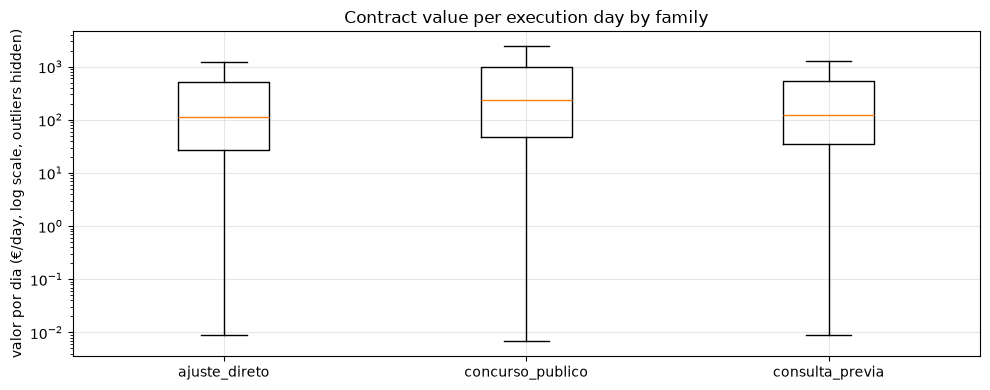

In [8]:
# Execution time and value per day by family (valor_por_dia only for 1..3650 days).
display(fam.group_by("family").agg(
    pl.col("prazo_execucao").median().alias("median_prazo_days"),
    pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
    pl.col("valor_por_dia").quantile(0.9).round(2).alias("p90_eur_per_day"),
    pl.col("valor_por_dia").is_not_null().mean().round(3).alias("share_defined"),
))
fd = fam.filter(pl.col("valor_por_dia") > 0)
fig, ax = plt.subplots()
ax.boxplot([fd.filter(pl.col("family") == f)["valor_por_dia"].to_numpy() for f in FAMILIES], tick_labels=FAMILIES, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("valor por dia (€/day, log scale, outliers hidden)")
ax.set_title("Contract value per execution day by family")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

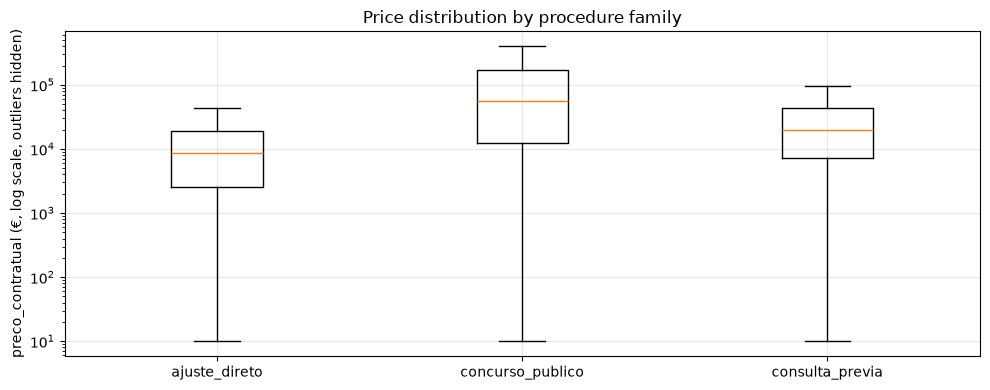

family,p10,p25,p50,p75,p90,p99
str,f64,f64,f64,f64,f64,f64
"""concurso_publico""",2199.5,12208.0,55857.6,168395.86,445112.0,3.669e6
"""ajuste_direto""",396.69,2561.34,8700.0,18930.55,45000.0,272439.74
"""consulta_previa""",1932.1,7222.5,19900.0,42983.0,72000.0,149547.34


In [9]:
pos = fam.filter(pl.col("preco_contratual") > 0)
data = [pos.filter(pl.col("family") == f)["preco_contratual"].to_numpy() for f in FAMILIES]
fig, ax = plt.subplots()
ax.boxplot(data, tick_labels=FAMILIES, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("preco_contratual (€, log scale, outliers hidden)")
ax.set_title("Price distribution by procedure family")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(pos.group_by("family").agg(
    *[pl.col("preco_contratual").quantile(q).alias(f"p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9, 0.99)]
))

In [10]:
# tipo_contrato can hold several "\n"-separated values; a contract counts once per value.
mix = (
    fam.with_columns(pl.col("tipo_contrato").str.split("\n"))
    .explode("tipo_contrato")
    .group_by("family", "tipo_contrato").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("family") * 100).round(1).alias("pct"))
    .pivot(on="family", index="tipo_contrato", values="pct")
    .sort("ajuste_direto", descending=True, nulls_last=True)
)
mix

/var/folders/qm/v8q4c7z96x3___vhx5_pxyc00000gn/T/ipykernel_35133/2238473746.py:4: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  .explode("tipo_contrato")


tipo_contrato,consulta_previa,concurso_publico,ajuste_direto
str,f64,f64,f64
"""Aquisição de bens móveis""",42.5,51.3,46.9
"""Aquisição de serviços""",43.3,29.5,45.1
"""Empreitadas de obras públicas""",12.3,16.5,6.8
"""Locação de bens móveis""",1.6,2.1,0.9
"""Sociedade""",0.0,0.0,0.1
"""Concessão de obras públicas""",0.1,0.0,0.1
"""Concessão de serviços públicos""",0.1,0.3,0.1
"""Outros""",0.0,0.1,0.1
null,0.0,0.0,0.0


In [11]:
divs = (
    fam.with_columns(pl.col("cpv").str.slice(0, 2).alias("cpv_div"))
    .group_by("family", "cpv_div").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("family") * 100).round(1).alias("pct"))
)
for f in FAMILIES:
    print(f"Top 10 CPV divisions: {f}")
    display(divs.filter(pl.col("family") == f).sort("len", descending=True).head(10))

Top 10 CPV divisions: ajuste_direto


family,cpv_div,len,pct
str,str,u32,f64
"""ajuste_direto""","""cp""",1356997,100.0
"""ajuste_direto""",null,199,0.0


Top 10 CPV divisions: concurso_publico


family,cpv_div,len,pct
str,str,u32,f64
"""concurso_publico""","""cp""",267107,100.0
"""concurso_publico""",null,10,0.0


Top 10 CPV divisions: consulta_previa


family,cpv_div,len,pct
str,str,u32,f64
"""consulta_previa""","""cp""",334545,100.0
"""consulta_previa""",null,5,0.0


In [12]:
def concentration(df: pl.DataFrame, key: str) -> pl.DataFrame:
    """Per family: distinct entities, top-10 share of value and HHI of value shares."""
    by = df.group_by("family", key).agg(pl.col("preco_contratual").sum().alias("v"), pl.len().alias("n"))
    tot = by.with_columns((pl.col("v") / pl.col("v").sum().over("family")).alias("s"))
    return tot.group_by("family").agg(
        pl.len().alias("n_entities"),
        pl.col("s").sort(descending=True).head(10).sum().round(3).alias("top10_value_share"),
        (pl.col("s") ** 2).sum().round(4).alias("hhi_value"),
    )

print("Adjudicante (buyer) concentration by NIPC key:")
display(concentration(fam, "adjudicante_key"))
for f in FAMILIES:
    sub = fam.filter(pl.col("family") == f)
    top = (
        sub.group_by("adjudicante_key")
        .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(0).alias("total_value"))
        .join(canonical_names(sub, prefix="adjudicante"), on="adjudicante_key", how="left")
        .sort("total_value", descending=True).head(20)
    )
    print(f"Top 20 buyers by value: {f}")
    display(top)

Adjudicante (buyer) concentration by NIPC key:


family,n_entities,top10_value_share,hhi_value
str,u32,f64,f64
"""ajuste_direto""",9526,0.216,0.0077
"""concurso_publico""",3709,0.201,0.0119
"""consulta_previa""",6960,0.096,0.0024


Top 20 buyers by value: ajuste_direto


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""508481287""",27594,1.4093e9,"""Unidade Local de Saúde de Sant…"
"""510103448""",27269,1.3408e9,"""Unidade Local de Saúde de Coim…"
"""503933813""",3330,1.1857e9,"""Infraestruturas de Portugal, S…"
"""506362299""",73826,6.87487399e8,"""IPO Porto FG, EPE"""
"""508080142""",11806,6.82382614e8,"""Unidade Local de Saúde de São …"
"""500051070""",14077,5.41587885e8,"""Município de Lisboa"""
"""508142156""",41316,4.78865344e8,"""Unidade Local de Saúde de Gaia…"
"""600012662""",23407,4.68360816e8,"""MARINHA - Direção de Abastecim…"
"""509821197""",7574,4.5786061e8,"""Unidade Local de Saúde de São …"


Top 20 buyers by value: concurso_publico


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",2875,7.1345e9,"""Infraestruturas de Portugal, S…"
"""516150359""",48,1.2228e9,"""TML - Transportes Metropolitan…"
"""500051070""",1441,1.1928e9,"""Município de Lisboa"""
"""503278602""",48,1.1156e9,"""Metro do Porto, SA"""
"""500745471""",5589,1.0985e9,"""Santa Casa da Misericórdia de …"
"""600010686""",1425,8.380721e8,"""Estado Maior da Força Aérea"""
"""503450189""",506,7.36229494e8,"""Edia - Empresa de Desenvolvime…"
"""500192855""",245,7.30741063e8,"""Metropolitano de Lisboa, EPE"""
"""500745943""",1920,7.16848897e8,"""Município de Oeiras"""


Top 20 buyers by value: consulta_previa


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",987,2.41922909e8,"""Infraestruturas de Portugal, S…"
"""500051070""",2177,1.193457e8,"""Município de Lisboa"""
"""505187531""",1026,1.06833383e8,"""Município de Cascais"""
"""500745943""",1885,1.04045633e8,"""Município de Oeiras"""
"""506614913""",1395,9.0357488e7,"""Município de Vila Franca de Xi…"
"""506173968""",1531,8.8453724e7,"""Município do Seixal"""
"""500192855""",128,8.1345921e7,"""Metropolitano de Lisboa, EPE"""
"""511228848""",4872,8.1055064e7,"""Serviço de Saúde da Região Aut…"
"""504293125""",1186,7.8776568e7,"""Município de Odivelas"""


In [13]:
entries = entity_key(explode_entities(fam, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
entries = entries.join(fam.select("idcontrato", "family", "preco_contratual"), on="idcontrato", how="left")
print(entries["adjudicatarios_key_source"].value_counts(sort=True))
# Multi-awardee contract value counted in full for each awardee.
print("Adjudicatario (supplier) concentration by key (includes name-fallback keys):")
display(concentration(entries, "adjudicatarios_key"))
print("Same, NIPC-keyed suppliers only:")
display(concentration(entries.filter(pl.col("adjudicatarios_key_source") == "nipc"), "adjudicatarios_key"))
fam_sets = {f: set(entries.filter((pl.col("family") == f) & (pl.col("adjudicatarios_key_source") == "nipc"))["adjudicatarios_key"]) for f in FAMILIES}
in_all = set.intersection(*fam_sets.values())
print(f"NIPC suppliers in all three families: {len(in_all):,} of {len(set.union(*fam_sets.values())):,}")
for f in FAMILIES: print(f"  only in {f}: {len(fam_sets[f] - set.union(*(v for k, v in fam_sets.items() if k != f))):,}")

shape: (2, 2)
┌───────────────────────────┬─────────┐
│ adjudicatarios_key_source ┆ count   │
│ ---                       ┆ ---     │
│ str                       ┆ u32     │
╞═══════════════════════════╪═════════╡
│ nipc                      ┆ 1762228 │
│ name                      ┆ 218195  │
└───────────────────────────┴─────────┘
Adjudicatario (supplier) concentration by key (includes name-fallback keys):


family,n_entities,top10_value_share,hhi_value
str,u32,f64,f64
"""consulta_previa""",55065,0.053,0.0006
"""concurso_publico""",18659,0.102,0.0026
"""ajuste_direto""",163880,0.076,0.0015


Same, NIPC-keyed suppliers only:


family,n_entities,top10_value_share,hhi_value
str,u32,f64,f64
"""ajuste_direto""",84370,0.083,0.0018
"""concurso_publico""",15961,0.109,0.0028
"""consulta_previa""",39371,0.045,0.0005


NIPC suppliers in all three families: 11,106 of 92,609
  only in ajuste_direto: 48,873
  only in concurso_publico: 1,401
  only in consulta_previa: 6,348


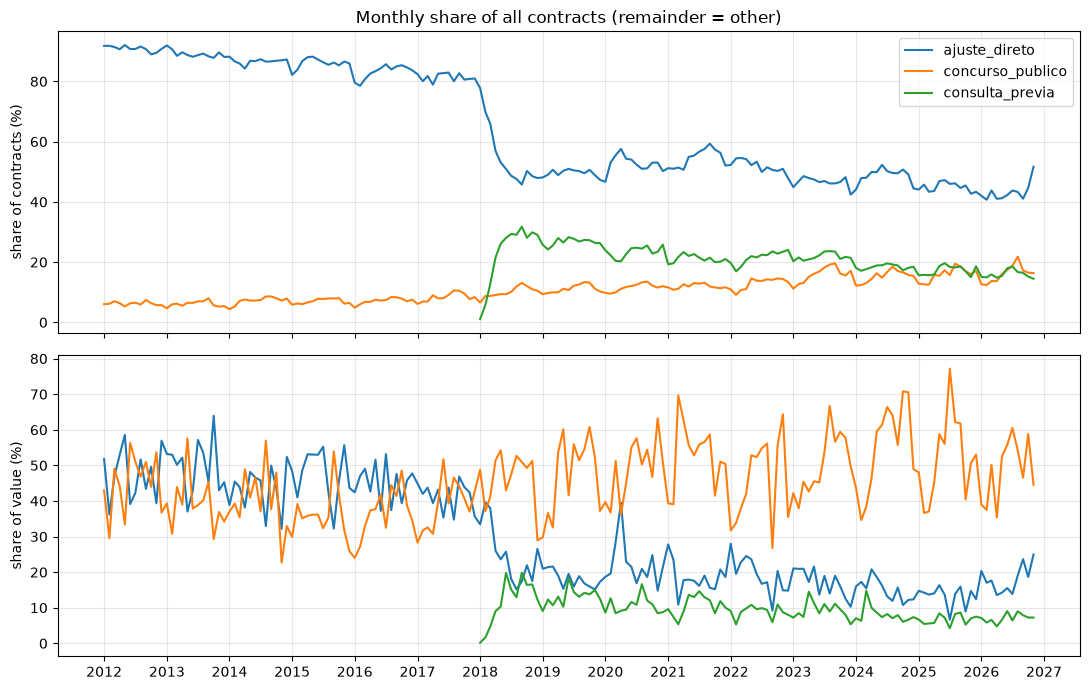

In [14]:
monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month", "family").agg(pl.len().alias("n"), pl.col("preco_contratual").sum().alias("v"))
    .with_columns(
        (pl.col("n") / pl.col("n").sum().over("month")).alias("count_share"),
        (pl.col("v") / pl.col("v").sum().over("month")).alias("value_share"),
    )
    .sort("month")
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for f in FAMILIES:
    m = monthly.filter(pl.col("family") == f)
    axes[0].plot(m["month"], m["count_share"] * 100, label=f)
    axes[1].plot(m["month"], m["value_share"] * 100, label=f)
axes[0].set_ylabel("share of contracts (%)")
axes[1].set_ylabel("share of value (%)")
axes[0].set_title("Monthly share of all contracts (remainder = other)")
axes[0].legend()
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# NUTS II (first 4 chars of the first NUTS value) share per family, in %.
geo = (
    fam.with_columns(pl.col("nuts").str.split("\n").list.first().str.slice(0, 4).fill_null("n/a").alias("nuts2"))
    .group_by("family", "nuts2").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("family") * 100).round(1).alias("pct"))
    .pivot(on="family", index="nuts2", values="pct")
    .sort("ajuste_direto", descending=True, nulls_last=True)
)
geo

nuts2,ajuste_direto,consulta_previa,concurso_publico
str,f64,f64,f64
"""n/a""",77.5,65.6,61.1
"""PT11""",8.2,10.5,10.8
"""PT17""",5.0,7.3,11.4
"""PT16""",3.5,7.2,5.5
"""PT18""",1.7,2.8,2.1
"""PT15""",1.2,1.6,2.0
"""PT20""",0.5,0.2,0.7
"""PT19""",0.5,0.9,1.1
"""PT1A""",0.5,0.7,1.5


In [16]:
from IPython.display import Markdown

LABEL = {"ajuste_direto": "Ajuste Direto", "concurso_publico": "Concurso público", "consulta_previa": "Consulta Prévia"}
by = lambda df, **kw: {r["family"]: r for r in df.to_dicts()}  # noqa: E731
h = by(headline)
pct = lambda x, d=1: f"{x * 100:.{d}f} %"  # noqa: E731
eur = lambda x: f"€{x / 1e6:.1f}M" if x >= 1e6 else (f"€{x / 1e3:.1f}k" if x >= 1e3 else f"€{x:,.0f}")  # noqa: E731

price = by(pos.group_by("family").agg(pl.col("preco_contratual").median().alias("med"), pl.col("preco_contratual").quantile(0.99).alias("p99")))
dur = by(fam.group_by("family").agg(pl.col("prazo_execucao").median().alias("prazo"), pl.col("valor_por_dia").median().alias("vpd")))
cb = by(concentration(fam, "adjudicante_key"))
cs = by(concentration(entries, "adjudicatarios_key"))
cn = by(concentration(entries.filter(pl.col("adjudicatarios_key_source") == "nipc"), "adjudicatarios_key"))
union = set.union(*fam_sets.values())
only = {f: len(fam_sets[f] - set.union(*(v for k, v in fam_sets.items() if k != f))) for f in FAMILIES}
n_name = entries.filter(pl.col("adjudicatarios_key_source") == "name").height


def top_buyers(f, k=3):
    sub = fam.filter(pl.col("family") == f)
    top = sub.group_by("adjudicante_key").agg(pl.col("preco_contratual").sum().alias("v")).sort("v", descending=True).head(k)
    names = top.join(canonical_names(sub, prefix="adjudicante"), on="adjudicante_key", how="left")
    return " · ".join(str(n) for n in names["adjudicante_name"].to_list())


ad = fam.filter(pl.col("family") == "ajuste_direto")
short = ad.filter(pl.col("prazo_execucao").is_between(1, 30))["valor_por_dia"].median()
long_ = ad.filter(pl.col("prazo_execucao").is_between(366, 3650))["valor_por_dia"].median()
nb_ = [r["n_entities"] for r in cb.values()]

Markdown(f"""## Synthesis

Shares below are of the three families combined ({fam.height:,} contracts with |value| ≥ €{MIN_VALUE:g}); the remainder is `other`.

**Where they are similar**
- Supplier bases overlap: {len(in_all):,} NIPC suppliers appear in all three families (of {len(union):,} NIPC suppliers seen).
- Every family is spread over many buyers ({min(nb_):,}–{max(nb_):,} NIPC-keyed adjudicantes).

**Where they differ**
- **Count vs value:** """ + "; ".join(f"{LABEL[f]} is {pct(h[f]['count_share'])} of contracts and {pct(h[f]['value_share'])} of value" for f in FAMILIES) + f""".
- **Price levels (median / p99):** """ + "; ".join(f"{LABEL[f]} {eur(price[f]['med'])} / {eur(price[f]['p99'])}" for f in FAMILIES) + """.
- **Buyer concentration (value, NIPC-keyed):** """ + "; ".join(f"{LABEL[f]} top-10 = {pct(cb[f]['top10_value_share'])} (HHI {cb[f]['hhi_value']:.3f})" for f in FAMILIES) + """. Largest buyers by value: """ + "; ".join(f"{LABEL[f]}: {top_buyers(f)}" for f in FAMILIES) + """.
- **Supplier concentration (NIPC-only):** """ + "; ".join(f"{LABEL[f]} top-10 = {pct(cn[f]['top10_value_share'])} (HHI {cn[f]['hhi_value']:.3f}, {cn[f]['n_entities']:,} suppliers)" for f in FAMILIES) + f""".
- **Supplier exclusivity:** """ + ", ".join(f"{only[f]:,} suppliers appear only in {LABEL[f]}" for f in FAMILIES) + f""".

Name-fallback suppliers ({n_name:,} of {entries.height:,} entries) are included in the first concentration table and excluded from the NIPC-only one.
- **Duration:** median `prazo_execucao` is """ + ", ".join(f"{dur[f]['prazo']:.0f} days for {LABEL[f]}" for f in FAMILIES) + """; median value per day is """ + ", ".join(f"{eur(dur[f]['vpd'])} ({LABEL[f]})" for f in FAMILIES) + f""". Short contracts carry high €/day (Ajuste Direto 1–30 d: {eur(short)}/day vs {eur(long_)}/day for 366–3650 d).""")


## Synthesis

Shares below are of the three families combined (1,958,863 contracts with |value| ≥ €10); the remainder is `other`.

**Where they are similar**
- Supplier bases overlap: 11,106 NIPC suppliers appear in all three families (of 92,609 NIPC suppliers seen).
- Every family is spread over many buyers (3,709–9,526 NIPC-keyed adjudicantes).

**Where they differ**
- **Count vs value:** Ajuste Direto is 69.3 % of contracts and 28.9 % of value; Concurso público is 13.6 % of contracts and 62.2 % of value; Consulta Prévia is 17.1 % of contracts and 9.0 % of value.
- **Price levels (median / p99):** Ajuste Direto €8.7k / €272.4k; Concurso público €55.9k / €3.7M; Consulta Prévia €19.9k / €149.5k.
- **Buyer concentration (value, NIPC-keyed):** Ajuste Direto top-10 = 21.6 % (HHI 0.008); Concurso público top-10 = 20.1 % (HHI 0.012); Consulta Prévia top-10 = 9.6 % (HHI 0.002). Largest buyers by value: Ajuste Direto: Unidade Local de Saúde de Santa Maria, EPE · Unidade Local de Saúde de Coimbra, EPE · Infraestruturas de Portugal, SA; Concurso público: Infraestruturas de Portugal, SA · TML - Transportes Metropolitanos de Lisboa, EMT, SA · Município de Lisboa; Consulta Prévia: Infraestruturas de Portugal, SA · Município de Lisboa · Município de Cascais.
- **Supplier concentration (NIPC-only):** Ajuste Direto top-10 = 8.3 % (HHI 0.002, 84,370 suppliers); Concurso público top-10 = 10.9 % (HHI 0.003, 15,961 suppliers); Consulta Prévia top-10 = 4.5 % (HHI 0.001, 39,371 suppliers).
- **Supplier exclusivity:** 48,873 suppliers appear only in Ajuste Direto, 1,401 suppliers appear only in Concurso público, 6,348 suppliers appear only in Consulta Prévia.

Name-fallback suppliers (218,195 of 1,980,423 entries) are included in the first concentration table and excluded from the NIPC-only one.
- **Duration:** median `prazo_execucao` is 60 days for Ajuste Direto, 292 days for Concurso público, 152 days for Consulta Prévia; median value per day is €111 (Ajuste Direto), €233 (Concurso público), €122 (Consulta Prévia). Short contracts carry high €/day (Ajuste Direto 1–30 d: €438/day vs €22/day for 366–3650 d).

## Limitations

- `Ano` covers 2012–2026 (data up to 2026-11-14); edge months are partial.
- Supplier value counts a multi-awardee contract in full for each awardee.
- Name-fallback (`-` NIPC) suppliers are mostly individuals; similarity clustering may over- or under-merge, so a NIPC-only view is shown too.
- Prices are not adjusted for contract duration; CCP thresholds push low values to Ajuste Direto by design.
- Contracts with |value| below €10 are disregarded (see the per-family before/after cell); `valor_por_dia` uses only 1–3650-day durations.